# Mini Project 2: House Price Prediction Model
**Week 2 – Supervised Learning (Regression)**

**Tasks:** train a Linear Regression model → predict house prices → evaluate R² → plot predicted vs actual.

**Dataset:** Kaggle – House Prices. If you place Kaggle's `train.csv` (target `SalePrice`) in `data/`, the notebook uses it automatically. Otherwise it uses the Kaggle *House Sales in King County* data (`data/kc_house_data.csv`, target `price`) so it runs out of the box.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style('whitegrid')

## 1. Load the data

In [2]:
if os.path.exists('data/train.csv'):
    df = pd.read_csv('data/train.csv'); TARGET = 'SalePrice'
else:
    df = pd.read_csv('data/kc_house_data.csv'); TARGET = 'price'
print('Target:', TARGET, '| Shape:', df.shape)
df.head()

Target: price | Shape: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## 2. Explore & clean

count    2.161300e+04
mean     5.400881e+05
std      3.671272e+05
min      7.500000e+04
25%      3.219500e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64

Missing values (top 5):
id           0
date         0
price        0
bedrooms     0
bathrooms    0
dtype: int64


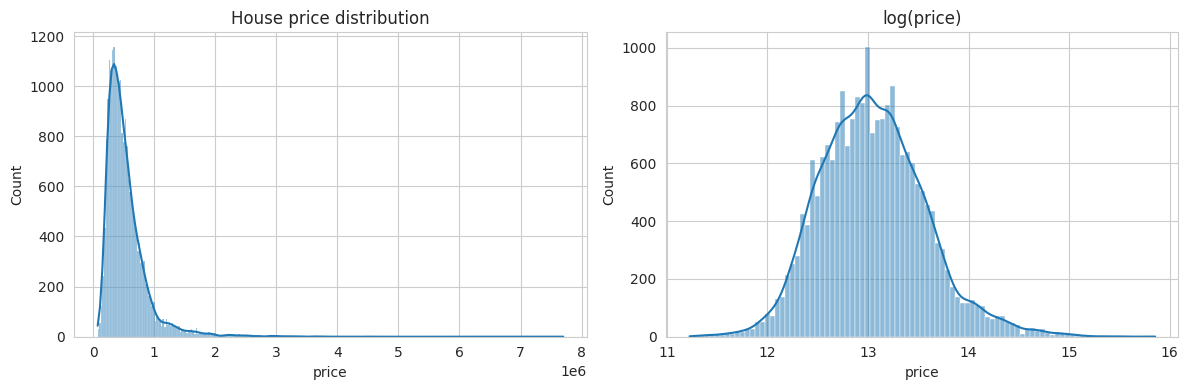

In [3]:
print(df[TARGET].describe())
print('\nMissing values (top 5):')
print(df.isnull().sum().sort_values(ascending=False).head(5))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], kde=True, ax=ax[0]); ax[0].set_title('House price distribution')
sns.histplot(np.log1p(df[TARGET]), kde=True, ax=ax[1]); ax[1].set_title('log(price)')
plt.tight_layout(); plt.savefig('images/price_distribution.png', dpi=120); plt.show()

In [4]:
# Keep numeric columns only, drop ID-like / non-informative columns, fill missing with median
X = df.select_dtypes(include='number').drop(columns=[TARGET])
X = X.drop(columns=[c for c in ['id','Id','zipcode','lat','long'] if c in X.columns])
X = X.fillna(X.median())
y = df[TARGET]
print('Features used:', X.shape[1])

corr = X.corrwith(y).sort_values(ascending=False)
print('\nTop correlations with price:')
print(corr.head(6))

Features used: 15

Top correlations with price:
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525138
view             0.397293
dtype: float64


## 3. Train / test split and Linear Regression

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
print('Train size:', X_train.shape, '| Test size:', X_test.shape)

Train size: (17290, 15) | Test size: (4323, 15)


## 4. Predict house prices

In [6]:
y_pred = model.predict(X_test)
pd.DataFrame({'Actual': y_test.values[:8], 'Predicted': y_pred[:8].round(0)})

,Actual,Predicted
0,365000.0,526523.0
1,865000.0,685644.0
2,1038000.0,1226282.0
3,1490000.0,1589230.0
4,711000.0,687641.0
5,211000.0,348661.0
6,790000.0,752355.0
7,680000.0,456203.0


## 5. Evaluate (R², MSE, RMSE, MAE)

In [7]:
mse = mean_squared_error(y_test, y_pred)
print(f'R² (test)  : {r2_score(y_test, y_pred):.4f}')
print(f'R² (train) : {model.score(X_train, y_train):.4f}')
print(f'MSE        : {mse:,.0f}')
print(f'RMSE       : {np.sqrt(mse):,.0f}')
print(f'MAE        : {mean_absolute_error(y_test, y_pred):,.0f}')

R² (test)  : 0.6541
R² (train) : 0.6534
MSE        : 52,291,717,659
RMSE       : 228,674
MAE        : 143,188


## 6. Plot predicted vs actual

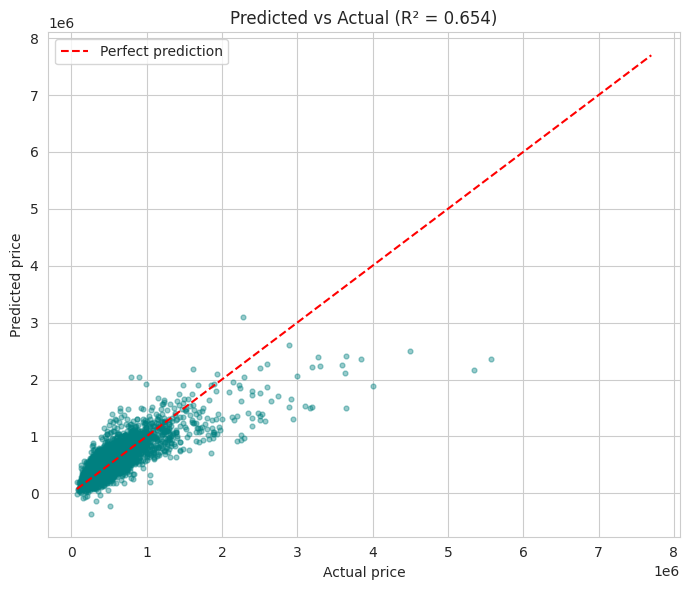

In [8]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.4, s=12, color='teal')
lim = [y.min(), y.max()]
plt.plot(lim, lim, 'r--', label='Perfect prediction')
plt.xlabel('Actual price'); plt.ylabel('Predicted price')
plt.title(f'Predicted vs Actual (R² = {r2_score(y_test, y_pred):.3f})')
plt.legend(); plt.tight_layout()
plt.savefig('images/predicted_vs_actual.png', dpi=120); plt.show()

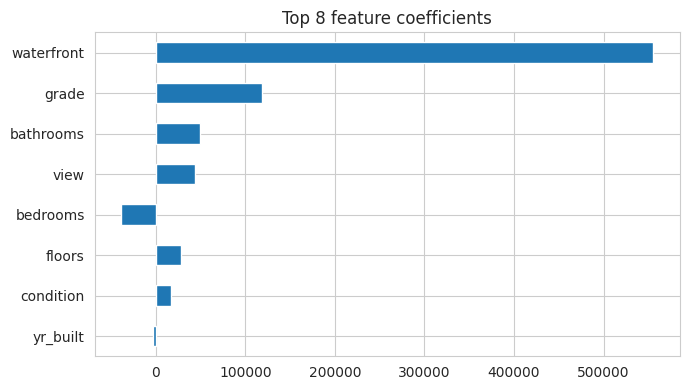

In [9]:
coef = pd.Series(model.coef_, index=X.columns).sort_values(key=abs, ascending=False).head(8)
coef.plot(kind='barh', figsize=(7, 4), title='Top 8 feature coefficients'); plt.gca().invert_yaxis()
plt.tight_layout(); plt.savefig('images/coefficients.png', dpi=120); plt.show()

## 7. Conclusion
- A Linear Regression model on the numeric features explains a good share of the variation in price (see R² above).
- The predicted-vs-actual plot follows the red line loosely: errors grow for expensive houses because price is right-skewed and the relationship isn't perfectly linear (RMSE is large relative to the median price).
- **Next steps:** log-transform the target, encode categorical features, and try Random Forest (covered in this week's topics).